# Documento de trabajo para VECM (Vector Error Correction Model)

Descripcion del análsis: Escribe la descripcion y objetivo del análisis.

Justificación del modelo: Escribe la justificación de porque se eligió este modelo

Autor: Escribe tu nombre aquí

Fecha de creación: Escribe la fecha de creación (YYYY-MM-DD)

Fecha de última actualización: Escribe la fecha de creación (YYYY-MM-DD)

### 1. Descripción del modelo

El **Modelo Vectorial de Correccion del Error (VECM)** es un modelo econométrico multivariado diseñado para analizar series de tiempo no estacionarias que mantienen una relación de equilibrio a largo plazo (cointegración), permitiendo estudiar tanto su dinámica de corto plazo como su velocidad de ajuste hacia dicho equilibrio.


Cuando trabajas con series financieras o macroeconómicas (ej. tasas de interés, PIB, inversión, tipos de cambio), estas suelen tener raíces unitarias, es decir, son integradas de orden uno, $I(1)$.

* Si estimas un modelo **Vectores Autoregresivos (VAR)** en niveles con series $I(1)$, se suele incurrir en **regresión espuria**.
* Si diferencias las series para volverlas estacionarias $I(0)$ y estimas un VAR en diferencias, pierdes toda la información sobre la relación de largo plazo entre ellas.

El **VECM** resuelve este problema integrando en una sola ecuación las primeras diferencias (dinámica de corto plazo) y los rezagos de las variables en niveles combinados linealmente (el término de corrección de error o equilibrio de largo plazo).

---

### 2. Especificación Matemática

Partiendo de un modelo $\text{VAR}(p)$ en niveles para un vector de $k$ variables endógenas $Y_t$:

$$Y_t = c + A_1 Y_{t-1} + A_2 Y_{t-2} + \dots + A_p Y_{t-p} + \varepsilon_t$$

Al restar $Y_{t-1}$ a ambos lados y reparametrizar, se obtiene la forma **VECM**:

$$\Delta Y_t = c + \Pi Y_{t-1} + \sum_{i=1}^{p-1} \Gamma_i \Delta Y_{t-i} + \varepsilon_t$$

Donde:

* $\Delta Y_t$: Vector $(k \times 1)$ de las primeras diferencias de las variables endógenas.
* $c$: Vector $(k \times 1)$ de términos determinísticos (interceptos o tendencias).
* $\Gamma_i = -\sum_{j=i+1}^p A_j$: Matrices $(k \times k)$ que capturan los **efectos dinámicos de corto plazo**.
* $\Pi = \sum_{i=1}^p A_i - I$: Matriz $(k \times k)$ de **impacto de largo plazo**. Si existe cointegración, el rango $r$ de $\Pi$ cumple $0 < r < k$, y se descompone como:

$$\Pi = \alpha \beta'$$

* $\beta$: Matriz $(k \times r)$ de **vectores de cointegración** (relaciones de equilibrio de largo plazo). Así, $\beta' Y_{t-1}$ representa el **Término de Corrección de Error (ECT)**.
* $\alpha$: Matriz $(k \times r)$ de **velocidades de ajuste** (loading matrix), que mide qué tan rápido cada variable corrige los desequilibrios del periodo anterior para volver al equilibrio de largo plazo.
* $\varepsilon_t \sim \mathcal{N}(0, \Sigma)$: Vector de innovaciones o choques de ruido blanco.

---

### 3. Ruta Crítica y Pruebas Necesarias (Paso a Paso)

Para especificar y validar correctamente un VECM, debes ejecutar las siguientes pruebas en orden estricto:

1. **Pruebas de Raíz Unitaria (Orden de Integración):**
* **Objetivo:** Verificar que todas las variables endógenas sean no estacionarias en niveles, específicamente $I(1)$, y estacionarias en primera diferencia $I(0)$.
* **Pruebas:** Augmented Dickey-Fuller (**ADF**), Phillips-Perron (**PP**) y **KPSS** (cuya hipótesis nula es estacionariedad, útil para confirmar ADF).


2. **Selección de Rezagos Óptimos ($p$):**
* **Objetivo:** Determinar el número de rezagos del VAR subyacente en niveles antes de diferenciar (el VECM usará $p - 1$ rezagos en diferencias).
* **Criterios:** Criterio de Información de Akaike (**AIC**), Bayesiano de Schwarz (**BIC/SC**) y Hannan-Quinn (**HQ**).


3. **Prueba de Cointegración de Johansen:**
* **Objetivo:** Determinar el rango $r$ de la matriz $\Pi$ (cuántos vectores de cointegración linealmente independientes existen) y la especificación determinística (sin intercepto, intercepto restringido al ECT, tendencia lineal, etc. - *Criterio de Pantula*).
* **Estadísticos:** Prueba de la **Traza** ($\lambda_{\text{trace}}$) y del **Máximo Valor Propio** ($\lambda_{\text{max}}$).


4. **Estimación del VECM y Validación de Signos en $\alpha$:**
* **Objetivo:** Verificar que al menos uno de los coeficientes de velocidad de ajuste ($\alpha_i$) sea estadísticamente significativo y tenga signo negativo respecto al desequilibrio (garantizando convergencia al equilibrio y no explosividad).


5. **Pruebas de Diagnóstico sobre los Residuales ($\hat{\varepsilon}_t$):**
* **Autocorrelación serial:** Prueba de **Portmanteau** o multiplicador de Lagrange (**LM de Breusch-Godfrey**). No debe haber correlación serial.
* **Heterocedasticidad:** Prueba multivariada de **White** o **ARCH-LM**.
* **Normalidad:** Prueba multivariada de **Jarque-Bera** (el incumplimiento no sesga los parámetros, pero afecta los intervalos de confianza).
* **Estabilidad del sistema:** Verificar que las raíces inversas del polinomio característico caigan dentro del círculo unitario (para un VECM con $k$ variables y $r$ relaciones de cointegración, habrá exactamente $k - r$ raíces unitarias y el resto deben ser menores a 1 en módulo).



---

### 4. Herramientas de Análisis Posterior

Una vez validado el modelo, la interpretación económica se realiza mediante:

* **Funciones de Impulso-Respuesta (IRF):** Muestran cómo reacciona cada variable a lo largo del tiempo ante un choque estructural (usualmente ortogonalizado mediante descomposición de Cholesky) en otra variable. A diferencia de un VAR en diferencias, en un VECM los choques pueden tener efectos permanentes.
* **Descomposición de la Varianza del Error de Pronóstico (FEVD):** Indica qué porcentaje de la variabilidad futura de una variable es explicada por sus propios choques frente a los choques de las demás variables del sistema.
* **Causalidad de Granger:** Evaluada tanto en el corto plazo (significancia conjunta de los $\Gamma_i$) como en el largo plazo (significancia de los $\alpha$).


In [ ]:
import os
from pyprojroot import here

os.chdir(here() / "src")
print("Nuevo directorio:", os.getcwd())

Nuevo directorio: c:\ABM\Analisis\Sensibilidades_inversion\src


In [3]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen

from services.api_service import inegi_bie


In [ ]:
series_id = {'736181': 'PIB',
             '737501': 'FBCF_privada',
             '737494': 'FBCF_publica',
             }


series = inegi_bie.get_series_data(list(series_id.keys()))

series.rename(columns=series_id, inplace=True)
series = series.asfreq('QS-MAR')

In [5]:
series.tail()

,PIB,FBCF_privada,FBCF_publica
2025-06-01,2.548058e+07,5.036727e+06,739852.515860
2025-09-01,2.545387e+07,5.031945e+06,720307.336299
2025-12-01,2.569449e+07,5.042852e+06,747237.886804
2026-03-01,2.560645e+07,4.921836e+06,813285.163116
2026-06-01,2.597119e+07,5.134707e+06,848902.993521


## Preparación de las series y visualización rápida

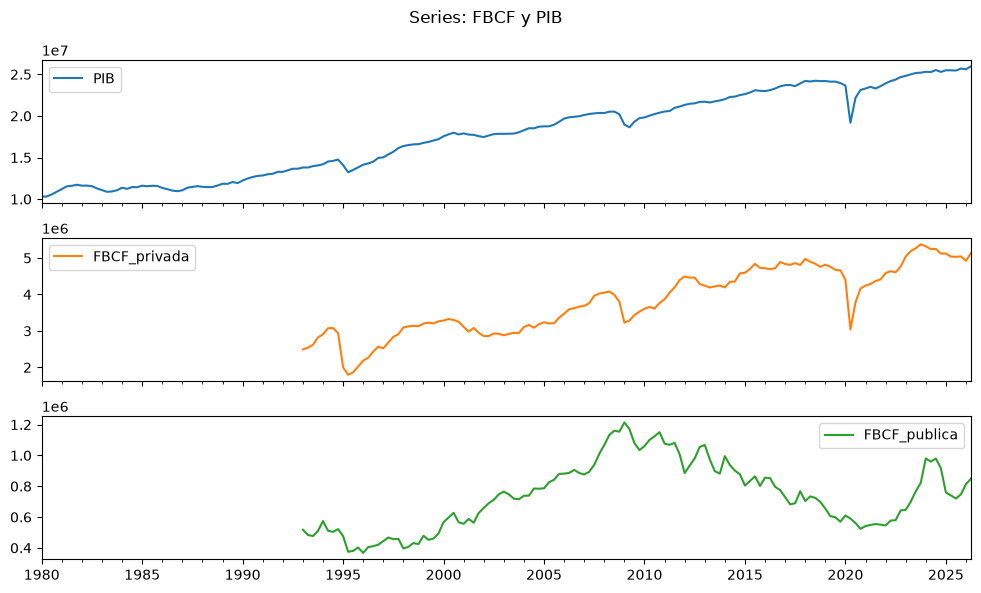

In [6]:

series.plot(subplots=True, figsize=(10,6), title='Series: FBCF y PIB')
plt.tight_layout()
plt.show()

## 1) Pruebas de estacionariedad (ADF) en niveles y en primeras diferencias

In [7]:
# Prueba de raíz unitaria ADF para cada serie y su primera diferencia
def adf_test(x, name='series'):
    x = x.dropna()
    res_n = adfuller(x, autolag='AIC', result_object=False, regression='n')
    res_c = adfuller(x, autolag='AIC', result_object=False, regression='c')
    res_ct = adfuller(x, autolag='AIC', result_object=False, regression='ct')
    res_ctt = adfuller(x, autolag='AIC', result_object=False, regression='ctt')
    print(f'{name} (n): ADF stat = {res_n[0]:.4f}, p-value = {res_n[1]:.4f}, usedlag = {res_n[2]}')
    print(f'{name} (c): ADF stat = {res_c[0]:.4f}, p-value = {res_c[1]:.4f}, usedlag = {res_c[2]}')
    print(f'{name} (ct): ADF stat = {res_ct[0]:.4f}, p-value = {res_ct[1]:.4f}, usedlag = {res_ct[2]}')
    print(f'{name} (ctt): ADF stat = {res_ctt[0]:.4f}, p-value = {res_ctt[1]:.4f}, usedlag = {res_ctt[2]}')

for col in series.columns:
    print('\n---', col, ' (niveles)')
    adf_test(np.log(series[col]), col + ' (niveles)')
    print(col, ' (1ª diferencia)')
    adf_test(np.log(series[col]).diff().dropna(), col + ' (diff)')



--- PIB  (niveles)
PIB (niveles) (n): ADF stat = 3.1126, p-value = 0.9999, usedlag = 1
PIB (niveles) (c): ADF stat = -1.0596, p-value = 0.7309, usedlag = 1
PIB (niveles) (ct): ADF stat = -2.7868, p-value = 0.2019, usedlag = 0
PIB (niveles) (ctt): ADF stat = -3.4867, p-value = 0.1163, usedlag = 0
PIB  (1ª diferencia)
PIB (diff) (n): ADF stat = -14.1674, p-value = 0.0000, usedlag = 0
PIB (diff) (c): ADF stat = -14.8389, p-value = 0.0000, usedlag = 0
PIB (diff) (ct): ADF stat = -14.8244, p-value = 0.0000, usedlag = 0
PIB (diff) (ctt): ADF stat = -14.7907, p-value = 0.0000, usedlag = 0

--- FBCF_privada  (niveles)
FBCF_privada (niveles) (n): ADF stat = 1.0031, p-value = 0.9164, usedlag = 0
FBCF_privada (niveles) (c): ADF stat = -1.5543, p-value = 0.5065, usedlag = 0
FBCF_privada (niveles) (ct): ADF stat = -3.2913, p-value = 0.0677, usedlag = 0
FBCF_privada (niveles) (ctt): ADF stat = -3.4699, p-value = 0.1207, usedlag = 0
FBCF_privada  (1ª diferencia)
FBCF_privada (diff) (n): ADF stat = -

### Observaciones: 

De acuerdo con los resultados de las pruebas, las series en logaritmo en primeras diferencias si son estacionarias, con la especificacion de que la inversion publica es estacionaria cuando no se considera una constante o tendencia deterministica

## 2) Selección de rezagos y prueba de cointegración (Johansen)

In [ ]:

# Series transformada (logaritmo natural)
series_log = np.log(series).dropna()

# Selección de rezagos usando el VAR
var_model = VAR(series_log).select_order(maxlags=8)

print('Selección de rezagos (por criterio):')
print(var_model.summary())


# Extracción del rezago elegido por AIC
selected = getattr(var_model, 'selected_orders', None)

if selected is not None:
    p_aic = selected.get('aic', 4)

    try:
        p_aic = var_model.aic
    except Exception as e: # noqa: BLE001
        p_aic = 4
        print(f"[Advertencia] No se pudo obtener el rezago óptimo por AIC, se usará el valor por defecto. Detalle: {e}")


print('Lag elegido (AIC):', p_aic)
k_ar_diff = max(int(p_aic) - 1, 1)
print('k_ar_diff (para Johansen / VECM):', k_ar_diff)


Selección de rezagos (por criterio):
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -11.91      -11.84   6.749e-06      -11.88
1      -19.56      -19.29   3.205e-09      -19.45
2     -19.83*     -19.35*  2.454e-09*     -19.63*
3      -19.76      -19.08   2.631e-09      -19.48
4      -19.68      -18.80   2.845e-09      -19.32
5      -19.73      -18.65   2.699e-09      -19.30
6      -19.63      -18.35   3.006e-09      -19.11
7      -19.56      -18.08   3.231e-09      -18.96
8      -19.48      -17.79   3.516e-09      -18.80
-------------------------------------------------
Lag elegido (AIC): 2
k_ar_diff (para Johansen / VECM): 1


In [9]:
# Variables de salida para uso en prueba de cointegracion y modelos VECM
selected_k = 3

In [10]:
# Prueba de Johansen en series en niveles (logaritmizadas)
jres = coint_johansen(series_log, det_order=1, k_ar_diff=selected_k)

print(f'\nJohansen test results with selected_k = {selected_k}:')
print('\nEigenvalues:', jres.eig)
print('\nTrace statistics (lr1):', jres.lr1)
print('\nCritical values (90%,95%,99%): \n', jres.cvt)


# Rango de cointegración: Valores de traza > valor crítico al 95% (índice 1)
cointegration_rank = sum(jres.lr1 > jres.cvt[:, 1])
print(f"\nRango de cointegración estimado (95%): {cointegration_rank}")




Johansen test results with selected_k = 3:

Eigenvalues: [0.16362989+0.j 0.06224698+0.j 0.0282252 +0.j]

Trace statistics (lr1): [35.3059079  12.07698099  3.72205461]

Critical values (90%,95%,99%): 
 [[32.0645 35.0116 41.0815]
 [16.1619 18.3985 23.1485]
 [ 2.7055  3.8415  6.6349]]

Rango de cointegración estimado (95%): 1


c:\ABM\Analisis\Sensibilidades_inversion\.venv\Lib\site-packages\statsmodels\tsa\vector_ar\vecm.py:717: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -t * np.sum(tmp, 0)
c:\ABM\Analisis\Sensibilidades_inversion\.venv\Lib\site-packages\statsmodels\tsa\vector_ar\vecm.py:718: ComplexWarning: Casting complex values to real discards the imaginary part
  lr2[i] = -t * np.log(1 - a[i])


### Observaciones: 

De acuerdo con los criterios de información (AIC, BIC, FPE y HQIC), se determinó que el orden de rezago óptimo matemático para el sistema es $p=2$, indicando que la dinámica de corto plazo de las variables se explica con una memoria de dos trimestres (seis meses). Sin embargo, dada la naturaleza macroeconómica y trimestral de las series de inversión y producto, las cuales suelen presentar un fuerte componente cíclico y estacional, se optó por imponer un orden de 4 rezagos ($p=4$) para las estimaciones subsecuentes. Esta decisión permite capturar el ciclo anual completo y es una práctica estándar para garantizar que los residuales del modelo estén libres de autocorrelación

## 3) Ajuste del VECM (si hay cointegración) y verificación de supuestos

In [11]:
# Incorporamos variables indicadoras sobre crisis económicas

exog_variables = pd.DataFrame(index=series_log.index)

exog_variables['crisis_1995'] = 0
exog_variables['crisis_2001'] = 0
exog_variables['crisis_2008'] = 0
exog_variables['crisis_2020'] = 0

exog_variables.loc[exog_variables.index >= pd.Timestamp(1995, 3, 1), 'crisis_1995'] = 1
exog_variables.loc[exog_variables.index >= pd.Timestamp(2000, 12, 1), 'crisis_2001'] = 1
exog_variables.loc[exog_variables.index >= pd.Timestamp(2008, 12, 1), 'crisis_2008'] = 1
exog_variables.loc[exog_variables.index >= pd.Timestamp(2020, 3, 1), 'crisis_2020'] = 1

In [ ]:
# 1. Validación de cointegración
# El modelo VECM requiere que exista al menos un vector de cointegración
if globals().get('cointegration_rank', 0) >= 1:
    print(f"--- Ajustando modelo VECM (Rango = {cointegration_rank}) ---")
    
    # 2. Configuración y ajuste del modelo
    vecm_model = VECM(
        series_log, 
        k_ar_diff=selected_k, 
        coint_rank=1, 
        deterministic='cili',  # 'ci' = Constante dentro de la relación de cointegración
        exog=exog_variables
    )
    vecm_res = vecm_model.fit()
    print(vecm_res.summary())
    
    # 3. Estructuración de residuales para diagnóstico
    try:
        resid_df = pd.DataFrame(vecm_res.resid, columns=series.columns[:vecm_res.resid.shape[1]])
    except Exception: # noqa: BLE001
        resid_df = pd.DataFrame(vecm_res.resid)
        print("[Advertencia] No se pudieron asignar nombres de columnas a los residuales.")

    print('\n--- Diagnósticos de Residuales ---')

    # 1. Autocorrelación (Ljung-Box, lag=4)
    print("\n1. Autocorrelación (Ljung-Box, lag=4):")
    for col in resid_df.columns:
        try:
            # Compatible con diferentes versiones de statsmodels
            lb_test = acorr_ljungbox(resid_df[col].dropna(), lags=[4])
            p_val = lb_test['lb_pvalue'].iloc[0] if isinstance(lb_test, pd.DataFrame) else lb_test[1][0]
            print(f"   - {col}: p-value = {p_val:.4f}")
        except Exception as e: # noqa: BLE001
            print(f"   [Error] {col}: {e}")

    # 2. Heterocedasticidad (ARCH test)
    print("\n2. Heterocedasticidad (ARCH test):")
    for col in resid_df.columns:
        try:
            # Con result_object=False evitamos el FutureWarning (para versiones nuevas)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                stat, pval, _, _ = het_arch(resid_df[col].dropna())
            print(f"   - {col}: p-value = {pval:.4f}")
        except Exception as e: # noqa: BLE001
            print(f"   [Error] {col}: {e}")

    # 3. Normalidad (Jarque-Bera)
    print("\n3. Normalidad (Jarque-Bera):")
    for col in resid_df.columns:
        try:
            jb_stat, jb_pval = stats.jarque_bera(resid_df[col].dropna())
            print(f"   - {col}: Estadístico = {jb_stat:.4f} | p-value = {jb_pval:.4f}")
        except Exception as e: # noqa: BLE001
            print(f"   [Error] {col}: {e}")

--- Ajustando modelo VECM (Rango = 1) ---
 Det. terms outside the coint. relation & lagged endog. parameters for equation PIB
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
exog1               0.0173      0.013      1.361      0.174      -0.008       0.042
exog2              -0.0142      0.013     -1.115      0.265      -0.039       0.011
exog3               0.0002      0.007      0.036      0.971      -0.013       0.013
exog4              -0.0018      0.006     -0.304      0.761      -0.013       0.010
L1.PIB             -0.8514      0.163     -5.215      0.000      -1.171      -0.531
L1.FBCF_privada     0.3128      0.066      4.768      0.000       0.184       0.441
L1.FBCF_publica    -0.0228      0.035     -0.655      0.512      -0.091       0.045
L2.PIB             -0.4215      0.176     -2.394      0.017      -0.767      -0.076
L2.FBCF_privada     0.0913      0.

### Observaciones:

1. Relación de Largo Plazo (Vector de Cointegración)Ecuación Estructurada: Con el PIB normalizado como primera variable (beta.1 = 1.0000), la relación estática de equilibrio a largo plazo es:

$$PIB + 0.0170 \cdot FBCF\_publica - 0.4419 \cdot FBCF\_privada - 10.1266 - 0.0016 \cdot t = 0$$

Interpretación: Existe una relación significativa de largo plazo entre el producto y los componentes de inversión. El coeficiente de la inversión privada (beta.3 = -0.4419, $p = 0.000$) confirma que es un ancla estructural fundamental para el PIB, mientras que la tendencia determinística lineal (lin_trend = -0.0016, $p = 0.000$) capta la evolución tendencial secular del sistema.

2. Mecanismo de Corrección de Errores (Alphas)
- Ajuste del Producto: El coeficiente de carga para el PIB (alpha = 0.0347, $p = 0.825$) no es estadísticamente significativo, lo que indica que el producto actúa de forma débilmente exógena ante las desviaciones del equilibrio general.
- Dinámica del Sector Privado: La inversión privada presenta un coeficiente de ajuste masivo, positivo y altamente significativo (alpha = 1.6768, $p = 0.000$), lo que denota que es el sector privado el que absorbe dinámicamente el proceso de corrección para devolver el sistema a su trayectoria de largo plazo tras un choque.

3. Dinámica de Corto Plazo e Incidencia sobre el PIB
- Inversión Privada como Impulsor: El primer rezago de la inversión privada (L1.FBCF_privada = 0.3128, $p = 0.000$) ejerce un impacto directo, positivo y estadísticamente muy fuerte sobre el crecimiento trimestral del PIB.
- Inversión Pública: Los rezagos de la inversión pública no muestran coeficientes significativos sobre el PIB en el horizonte trimestral inmediato ($p > 0.51$).
- Inercia y Memoria del Producto: El propio PIB en sus rezagos (L1.PIB = -0.8514, $p = 0.000$; L2.PIB = -0.4215, $p = 0.017$) refleja una fuerte inercia de reversión y ajuste cíclico trimestre a trimestre.

4. Diagnósticos de Residuales:
- Autocorrelación (Ljung-Box): Controlada con éxito para el PIB ($p = 0.7569$) y la inversión privada ($p = 0.9839$), aunque persiste una leve traza de autocorrelación en la inversión pública ($p = 0.0297$).
- Heterocedasticidad (ARCH): Validada favorablemente para la estabilidad de la varianza en el PIB y la inversión privada ($p > 0.99$).
- Normalidad (Jarque-Bera): Se rechaza la normalidad en los residuales del PIB y la inversión privada ($p = 0.0000$), un comportamiento común en series macroeconómicas de alta frecuencia expuestas a choques estructurales históricos severos.

## 4) Respuestas a impulsos / sensibilidad del PIB ante shocks en FBCF pública y privada

<Figure size 1500x1500 with 0 Axes>

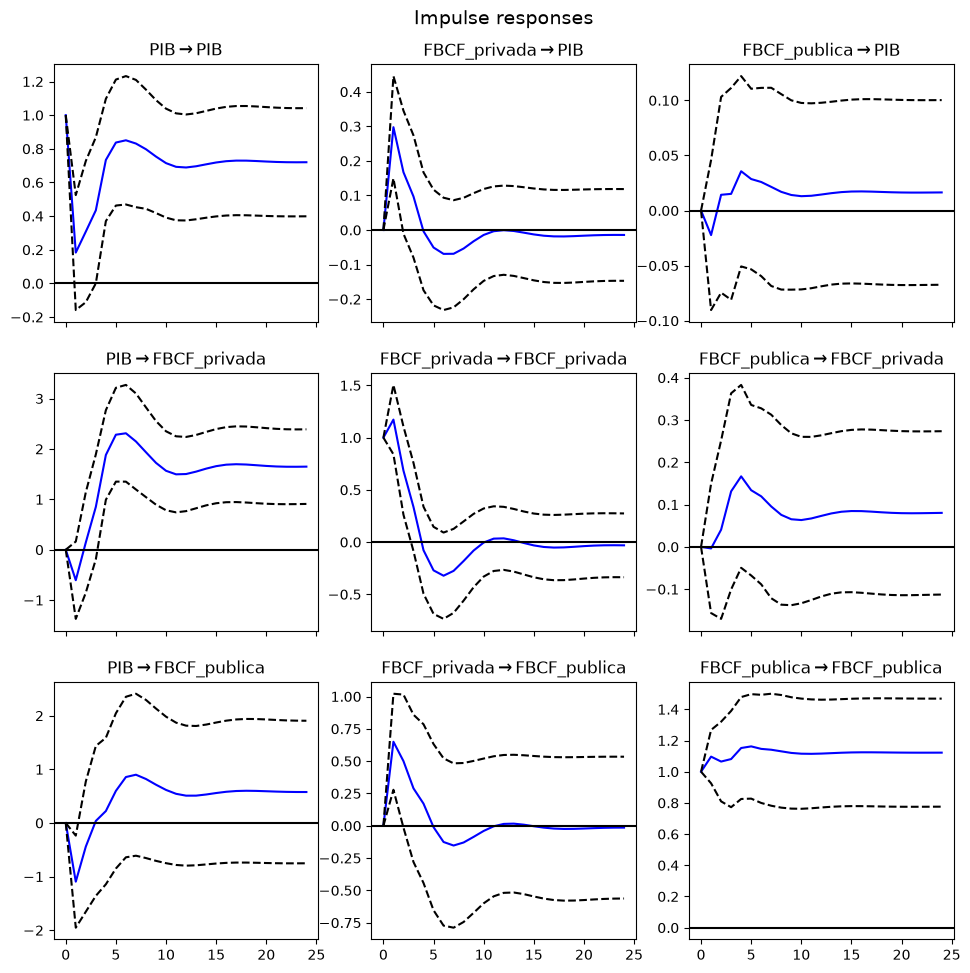

In [ ]:
if 'cointegration_rank' in globals() and cointegration_rank >= 1:
    try:
        irf = vecm_res.irf(24)
        irfs = getattr(irf, 'irfs', None)
    except Exception as e: # noqa: BLE001
        print(f'\nNo fue posible generar IRF con vecm_res.irf. Detalle: {e}')
        irfs = None
        
    if irfs is not None:
        plt.figure(figsize=(15, 15))
        fig = irf.plot(orth=False, signif=0.05)
        plt.show()

else:
    print('\nNo se detectó cointegración suficiente para generar IRF.')

In [ ]:
if 'cointegration_rank' in globals() and cointegration_rank >= 1:
    try:
        # ============================================================
        # IRFs
        # ============================================================
        irf = vecm_res.irf(12)
        irfs_array = irf.irfs

        cols = list(series.columns)
        steps = irfs_array.shape[0]

        # ============================================================
        # ERROR ESTÁNDAR DE LAS IRFs
        # ============================================================
        stderr = irf.stderr(orth=False)

        print("Dimensiones IRF:", irfs_array.shape)
        print("Dimensiones stderr:", stderr.shape)

        # ============================================================
        # INTERVALO DE CONFIANZA AL 95%
        # ============================================================
        z = 1.96

        lower = irfs_array - z * stderr
        upper = irfs_array + z * stderr

        # ============================================================
        # CONSTRUIR DATAFRAME
        # ============================================================
        records = []

        for t in range(steps):
            for r_idx, resp in enumerate(cols):
                for i_idx, imp in enumerate(cols):

                    records.append({
                        'Trimestre': t,
                        'Impulso': imp,
                        'Respuesta': resp,
                        'Valor': irfs_array[t, r_idx, i_idx],
                        'CI_Inferior': lower[t, r_idx, i_idx],
                        'CI_Superior': upper[t, r_idx, i_idx]
                    })

        df_irf = pd.DataFrame(records)

        # ============================================================
        # EXPORTAR A CSV
        # ============================================================
        output_csv = here() / "resultados/irf_datos_exactos.csv"

        df_irf.to_csv(
            output_csv,
            index=False
        )

        print(f"Datos exportados exitosamente a: {output_csv}")
        print(df_irf.head())

    except Exception as e: # noqa: BLE001
        print("Error al exportar las IRFs:", e)

Dimensiones IRF: (13, 3, 3)
Dimensiones stderr: (13, 3, 3)
Datos exportados exitosamente a: c:\ABM\Analisis\Sensibilidades_inversion\irf_datos_exactos.csv
   Trimestre       Impulso     Respuesta  Valor  CI_Inferior  CI_Superior
0          0           PIB           PIB    1.0          1.0          1.0
1          0  FBCF_privada           PIB    0.0          0.0          0.0
2          0  FBCF_publica           PIB    0.0          0.0          0.0
3          0           PIB  FBCF_privada    0.0          0.0          0.0
4          0  FBCF_privada  FBCF_privada    1.0          1.0          1.0


### Observaciones:

- Choque de Inversión Privada al PIB: El PIB experimenta un incremento masivo y acelerado durante el primer trimestre (alcanzando un pico de casi 0.30), seguido por una corrección cíclica natural que desciende por debajo de la línea base entre los trimestres 4 y 10, antes de converger nuevamente a cero. Esto refleja un ciclo de maduración y sobreajuste temporal de la capacidad productiva instalada. Esto puede deberse a efectos de inflación, sobreendeudamiento o capacidad productiva rebasada.

- Choque de Inversión Pública al PIB: Muestra un impacto inicial prácticamente nulo y ligeramente negativo en el primer trimestre, seguido por una trayectoria positiva moderada, sumamente estable y persistente a lo largo de todo el horizonte.


## Conclusiones:

Incidencia de la Inversión Pública y Privada en el PIB de México

1. Relación de Largo Plazo y Cointegración:
- Equilibrio Estructural: Las pruebas de raíces unitarias confirman que las series se integran en orden uno $I(1)$, y la prueba de Johansen valida la existencia de una relación de cointegración de largo plazo entre el PIB, la formación bruta de capital fijo privado y la pública.
- El Rol del Capital Privado: El vector estático de largo plazo muestra que la inversión privada ejerce un papel estructural fundamental como ancla del producto, confirmando su peso cuantitativo en la senda de crecimiento de la economía mexicana.
- Dinámica Secular: La inclusión de una tendencia determinística lineal permite capturar la evolución de la trayectoria de mediano y largo plazo del sistema económico.

2. Mecanismo de Corrección de Errores y Ajuste Estructural
- Exogeneidad de la Inversión Pública: Los coeficientes de ajuste (alphas) revelan que la inversión pública se comporta de manera exógena ante las desviaciones del equilibrio de largo plazo, lo que refleja que el gasto gubernamental responde principalmente a criterios presupuestales y políticos más que a fuerzas de autocorrección del mercado.
- Ajuste del Sector Privado: Es la inversión privada la que absorbe y lidera dinámicamente el proceso de corrección para retornar el sistema a su senda de equilibrio tras un choque macroeconómico.

3. Incidencia y Dinámica de Corto Plazo sobre el PIB
- La Inversión Privada como Motor Inmediato: En el plano trimestral, el primer rezago de la inversión privada ejerce un impacto directo, positivo y estadísticamente muy significativo sobre el crecimiento del PIB, consolidándose como el principal detonante de la actividad económica en el corto plazo.
- Ausencia de Arrastre Trimestral Público: Los rezagos de la inversión pública no muestran una incidencia trimestral inmediata y estadísticamente significativa sobre el producto, lo que evidencia que el gasto de capital del gobierno opera con periodos de maduración más largos.
- Efectos Cíclicos y de Crisis: La incorporación de variables indicadoras (dummies) para los periodos de crisis históricas permite aislar adecuadamente los choques extremos, capturando caídas abruptas y significativas en la actividad económica agregada.

4. Sensibilidad Dinámica (Funciones de Impulso-Respuesta)
- Respuesta Expansiva y Sobreajuste del Capital Privado: Ante un choque positivo en la inversión privada, el PIB reacciona con un fuerte impulso expansivo en los primeros trimestres, seguido por una fase de corrección cíclica y ajuste por capacidad ociosa antes de converger nuevamente a su estado estacionario.
- Estabilidad del Gasto Público: El choque en la inversión pública muestra una respuesta inicial poco significante pero sesgada positivamente y persistente a lo largo del horizonte temporal evaluado.
